In [13]:
import numpy as np
import plotly.graph_objects as go
import math
import plotly.io as pio
pio.renderers.default = "png"

# Example 8.1 : Dyna Maze

In [14]:
maxRowsDM, maxColsDM = 6, 9
maze = np.ones((maxRowsDM, maxColsDM), dtype=bool)
maze[1:4, 2] = False
maze[4, 5] = False
maze[0:3, 7] = False
startPos = (2, 0)
endPos = (0, 8)
UP, DOWN, RIGHT, LEFT = 0, 1, 2, 3

In [15]:
def plotMaze(maze, startPos, endPos):
    maxRows, maxCols = maze.shape

    fig = go.Figure()
    for row in range(maxRows):
        for col in range(maxCols):
            color = "white" if maze[row, col] else "grey"
            fig.add_shape(type="rect", x0=col - 0.5, y0=maxRows - row - 0.5, x1=col + 0.5, y1=maxRows - row + 0.5, line=dict(color="black", width=1), fillcolor=color)
            if (row, col) == startPos:
                fig.add_annotation(y=maxRows - row, x=col, text="S", showarrow=False, font=dict(size=13))
            if (row, col) == endPos:
                fig.add_annotation(y=maxRows - row, x=col, text="G", showarrow=False, font=dict(size=13))

    fig.update_layout(plot_bgcolor="white", width=600)
    fig.update_yaxes(scaleanchor="x", range=[0, maxRows+1])
    fig.update_xaxes(range=[-1, maxCols])
    fig.show()

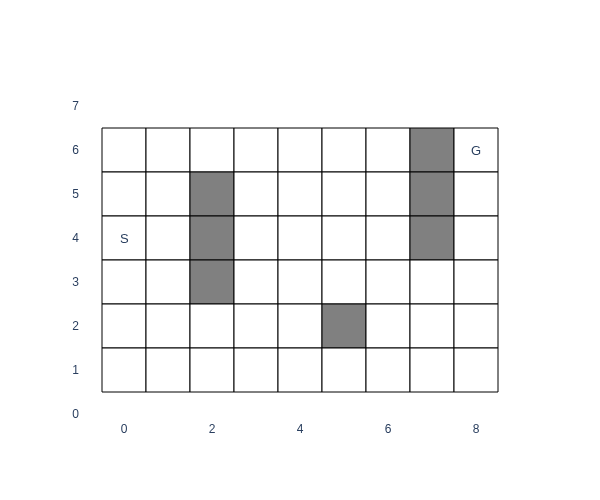

In [16]:
plotMaze(maze, startPos, endPos)

In [17]:
def encodeState(state, maxCol):
    return state[1] + maxCol * state[0]

def decodeState(state, maxCol):
    return state // maxCol, state % maxCol

def encodeStateAction(state, action, maxActions):
    return action + (maxActions + 1) * state

def decodeStateAction(stateAction, maxActions):
    return stateAction // (maxActions + 1), stateAction % (maxActions + 1)

In [18]:
def deriveNextState(currentPosition, action, maxRow, maxCol):
    row, col = currentPosition
    if action == UP:
        nextRow = row - 1
        nextCol = col
    elif action == DOWN:
        nextRow = row + 1
        nextCol = col
    elif action == RIGHT:
        nextRow = row
        nextCol = col + 1
    elif action == LEFT:
        nextRow = row
        nextCol = col - 1

    return min(max(int(nextRow), 0), maxRow - 1), min(max(int(nextCol), 0), maxCol - 1)

## Dyna-Q

In [19]:
def tabularDynaQDM(nEpisodes, qInit, modelInit, nPlanning, rngSeed, epsilon=0.1, alpha=0.1, gamma=0.95, availableActions=[UP, DOWN, RIGHT, LEFT]):
    Q = qInit.copy()
    model = modelInit.copy()
    np.random.seed(rngSeed)
    nSteps = np.zeros(nEpisodes, dtype=int)
    visited = set()
    visitedList = []

    for episode in range(nEpisodes):
        currentPosition = startPos
        currentState = encodeState(currentPosition, maxColsDM)
        terminal = False
        t = 0
        while not terminal:
            if np.random.rand() < epsilon:
                currentAction = np.random.choice(availableActions)
            else:
                currentAction = np.random.choice([action for action in availableActions if Q[currentState, action] == np.max(Q[currentState])])

            stateAction = encodeStateAction(currentState, currentAction, len(availableActions))
            if stateAction not in visited:
                visited.add(stateAction)
                visitedList.append(stateAction)

            t += 1
            nextPosition = deriveNextState(currentPosition, currentAction, maxRowsDM, maxColsDM)

            if not maze[*nextPosition]:
                nextPosition = currentPosition

            nextState = encodeState(nextPosition, maxColsDM)
            if nextPosition == endPos:
                terminal = True
                reward = 1
                update = 0

            else:
                reward = 0
                update = np.max(Q[nextState])

            Q[currentState, currentAction] += alpha * (reward + gamma * update - Q[currentState, currentAction])
            model[stateAction] = (reward, nextState)

            for n in range(nPlanning):
                stateAction = np.random.choice(visitedList)
                reward, statePrime = model[stateAction]
                state, action = decodeStateAction(stateAction, len(availableActions))
                Q[state, action] += alpha * (reward + gamma * np.max(Q[statePrime]) - Q[state, action])

            currentState = nextState
            currentPosition = decodeState(currentState, maxColsDM)

        nSteps[episode] = t            
    return nSteps

In [20]:
nStates = maxRowsDM * maxColsDM
nEpisodes = 50
availableActions=[UP, DOWN, RIGHT, LEFT]
qInit = np.zeros((nStates, len(availableActions)))
modelInit = {}
nReps = 30

nSteps0Planning = []
nSteps5Planning = []
nSteps50Planning = []
for rep in range(nReps):
    nSteps0Planning.append(tabularDynaQDM(nEpisodes, qInit, modelInit, 0, 10*rep))
    nSteps5Planning.append(tabularDynaQDM(nEpisodes, qInit, modelInit, 5, 10*rep))
    nSteps50Planning.append(tabularDynaQDM(nEpisodes, qInit, modelInit, 50, 10*rep))

nSteps0Planning = np.mean(nSteps0Planning, axis=0)
nSteps5Planning = np.mean(nSteps5Planning, axis=0)
nSteps50Planning = np.mean(nSteps50Planning, axis=0)

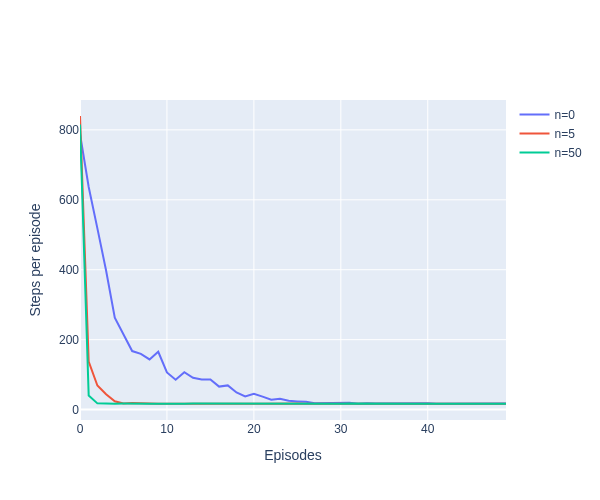

In [21]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=nSteps0Planning, name="n=0"))
fig.add_trace(go.Scatter(y=nSteps5Planning, name="n=5"))
fig.add_trace(go.Scatter(y=nSteps50Planning, name="n=50"))
fig.update_layout(xaxis_title="Episodes", yaxis_title="Steps per episode", width=600)
fig.show()

## $n$-step Q-learning

In [22]:
def nStepQLearningDM(nEpisodes, qInit, rngSeed, n, epsilon=0.1, alpha=0.1, gamma=0.95, availableActions=[UP, DOWN, RIGHT, LEFT]):
    Q = qInit.copy()
    np.random.seed(rngSeed)
    nSteps = np.empty(nEpisodes, dtype=int)

    for episode in range(nEpisodes):
        currentPosition = startPos
        currentState = encodeState(currentPosition, maxColsDM)
        t = 0
        T = np.inf
        completed = False
        stateTrajectory = []
        actionTrajectory = []
        rewardTrajectory = []

        stateTrajectory.append(currentState)
        while not completed:
            if t < T:
                if np.random.rand() < epsilon:
                    currentAction = np.random.choice(availableActions)
                else:
                    currentAction = np.random.choice([action for action in availableActions if Q[currentState, action] == np.max(Q[currentState])])

                actionTrajectory.append(currentAction)

                nextPosition = deriveNextState(currentPosition, currentAction, maxRowsDM, maxColsDM)

                if not maze[*nextPosition]:
                    nextPosition = currentPosition
                    
                nextState = encodeState(nextPosition, maxColsDM)
                if nextPosition == endPos:
                    reward = 1
                    T = t + 1
                else:
                    reward = 0

                rewardTrajectory.append(reward)
                currentState = nextState
                currentPosition = decodeState(nextState, maxColsDM)
                stateTrajectory.append(currentState)
            
            tau = t - n + 1
            if tau >= 0:
                gain = np.sum([gamma ** (i - tau) * rewardTrajectory[i] for i in range(tau, min(T, tau + n))])
                if tau + n < T:
                    gain += gamma ** n * np.max(Q[stateTrajectory[tau + n]])
                Q[stateTrajectory[tau], actionTrajectory[tau]] += alpha * (gain - Q[stateTrajectory[tau], actionTrajectory[tau]])

            completed = tau == T-1
            t += 1
        nSteps[episode] = T
    return nSteps

In [23]:
nStates = maxRowsDM * maxColsDM
nEpisodes = 50
availableActions=[UP, DOWN, RIGHT, LEFT]
qInit = np.zeros((nStates, len(availableActions)))
nReps = 30

nSteps5QLearning = []
nSteps20QLearning = []
nSteps50QLearning = []
for rep in range(nReps):
    nSteps5QLearning.append(nStepQLearningDM(nEpisodes, qInit, 10*rep, 5))
    nSteps20QLearning.append(nStepQLearningDM(nEpisodes, qInit, 10*rep, 20))
    nSteps50QLearning.append(nStepQLearningDM(nEpisodes, qInit, 10*rep, 50))

nSteps5QLearning = np.mean(nSteps5QLearning, axis=0)
nSteps20QLearning = np.mean(nSteps20QLearning, axis=0)
nSteps50QLearning = np.mean(nSteps50QLearning, axis=0)

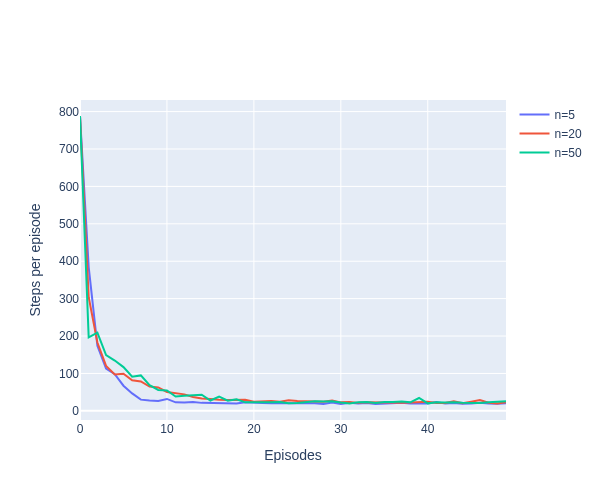

In [24]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=nSteps5QLearning, name="n=5"))
fig.add_trace(go.Scatter(y=nSteps20QLearning, name="n=20"))
fig.add_trace(go.Scatter(y=nSteps50QLearning, name="n=50"))
fig.update_layout(xaxis_title="Episodes", yaxis_title="Steps per episode", width=600)
fig.show()

# Example 8.2 : Blocking Maze

In [25]:
maxRowsDBM, maxColsDBM = 6, 9
blockingMaze1 = np.ones((maxRowsDBM, maxColsDBM), dtype=bool)
blockingMaze1[3, 0:8] = False
startPosDBM = (5, 3)
endPosDBM = (0, 8)
blockingMaze2 = np.ones((maxRowsDBM, maxColsDBM), dtype=bool)
blockingMaze2[3, 1:] = False
UP, DOWN, RIGHT, LEFT = 0, 1, 2, 3

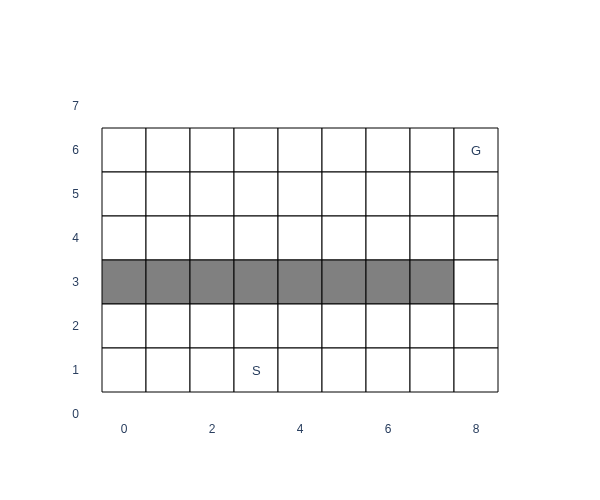

In [26]:
plotMaze(blockingMaze1, startPosDBM, endPosDBM)

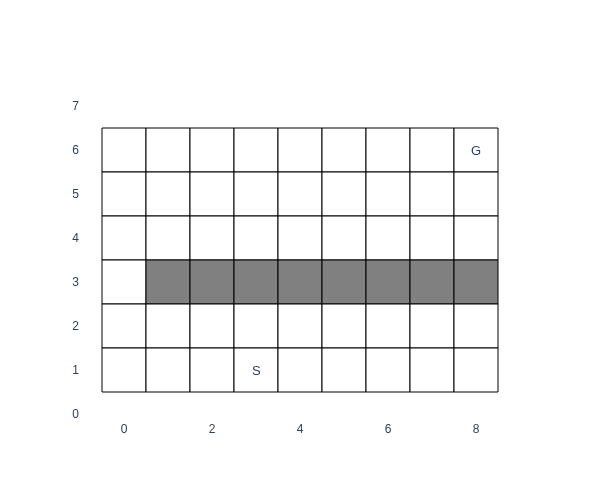

In [27]:
plotMaze(blockingMaze2, startPosDBM, endPosDBM)

In [28]:
def tabularDynaQDBM(nStepMax, qInit, modelInit, nPlanning, nSwitch, maze1, maze2, epsilon=0.1, alpha=0.1, gamma=0.95, availableActions=[UP, DOWN, RIGHT, LEFT]):
    Q = qInit.copy()
    model = modelInit.copy()
    nSteps = 0
    visited = set()
    visitedList = []
    currentMaze = maze1
    rewards = []

    while nSteps < nStepMax:
        currentPosition = startPosDBM
        traj = [currentPosition]
        currentState = encodeState(currentPosition, maxColsDBM)
        terminal = False
        t = 0
        while not terminal and nSteps < nStepMax:
            if nSteps == nSwitch:
                currentMaze = maze2

            if np.random.rand() < epsilon:
                currentAction = np.random.choice(availableActions)
            else:
                currentAction = np.random.choice([action for action in availableActions if Q[currentState, action] == np.max(Q[currentState])])

            stateAction = encodeStateAction(currentState, currentAction, len(availableActions))
            if stateAction not in visited:
                visited.add(stateAction)
                visitedList.append(stateAction)

            t += 1
            nextPosition = deriveNextState(currentPosition, currentAction, maxRowsDBM, maxColsDBM)
            nSteps += 1

            if not currentMaze[*nextPosition]:
                nextPosition = currentPosition

            nextState = encodeState(nextPosition, maxColsDBM)
            if nextPosition == endPosDBM:
                terminal = True
                reward = 1

            else:
                reward = 0

            rewards.append(reward)

            Q[currentState, currentAction] += alpha * (reward + gamma * np.max(Q[nextState]) - Q[currentState, currentAction])
            model[stateAction] = (reward, nextState)

            for n in range(nPlanning):
                stateAction = np.random.choice(visitedList)
                reward, statePrime = model[stateAction]
                state, action = decodeStateAction(stateAction, len(availableActions))
                Q[state, action] += alpha * (reward + gamma * np.max(Q[statePrime]) - Q[state, action])

            currentState = nextState
            currentPosition = decodeState(currentState, maxColsDBM)
            traj.append(currentPosition)

    return np.cumsum(rewards)

In [29]:
def tabularDynaQPlusDBM(nStepMax, qInit, modelInit, nPlanning, nSwitch, maze1, maze2, kappa=0.001, epsilon=0.1, alpha=0.1, gamma=0.95, availableActions=[UP, DOWN, RIGHT, LEFT]):
    Q = qInit.copy()
    model = modelInit.copy()
    nSteps = 0
    visited = set()
    visitedList = []
    currentMaze = maze1
    rewards = []
    tau = np.zeros(Q.shape, dtype=int)

    while nSteps < nStepMax:
        currentPosition = startPosDBM
        traj = [currentPosition]
        currentState = encodeState(currentPosition, maxColsDBM)
        terminal = False
        t = 0
        while not terminal and nSteps < nStepMax:
            if nSteps == nSwitch:
                currentMaze = maze2

            if np.random.rand() < epsilon:
                currentAction = np.random.choice(availableActions)
            else:
                currentAction = np.random.choice([action for action in availableActions if Q[currentState, action] == np.max(Q[currentState])])

            if currentState not in visited:
                visited.add(currentState)
                visitedList.append(currentState)

            t += 1
            nextPosition = deriveNextState(currentPosition, currentAction, maxRowsDBM, maxColsDBM)
            nSteps += 1

            if not currentMaze[*nextPosition]:
                nextPosition = currentPosition

            nextState = encodeState(nextPosition, maxColsDBM)
            if nextPosition == endPosDBM:
                terminal = True
                reward = 1

            else:
                reward = 0

            rewards.append(reward)

            Q[currentState, currentAction] += alpha * (reward + gamma * np.max(Q[nextState]) - Q[currentState, currentAction])

            stateAction = encodeStateAction(currentState, currentAction, len(availableActions))
            model[stateAction] = (reward, nextState)
            tau += 1
            tau[currentState, currentAction] = 0

            for n in range(nPlanning):
                state = np.random.choice(visitedList)
                action = np.random.choice(availableActions)
                reward, statePrime = model[encodeStateAction(state, action, len(availableActions))]
                reward += kappa * (tau[state, action] ** 0.5)
                Q[state, action] += alpha * (reward + gamma * np.max(Q[statePrime]) - Q[state, action])
            currentState = nextState
            currentPosition = decodeState(currentState, maxColsDBM)
            traj.append(currentPosition)
           
    return np.cumsum(rewards)

In [30]:
nStepMax = 3000
nStatesDBM = maxColsDBM * maxRowsDBM
availableActionsDBM = [UP, DOWN, RIGHT, LEFT]
qInitDBM = np.zeros((nStatesDBM, len(availableActionsDBM)))
modelInitDBM = {}
modelInitDBMPlus = {}
for state in range(nStatesDBM):
    for action in availableActionsDBM:
        modelInitDBMPlus[encodeStateAction(state, action, len(availableActionsDBM))] = (0, state)
nPlanningDBM = 10
rngSeed = 0
nSwitch = 1000
nRepsDBM = 10
alphaDBM = 1

dynaQDBM = []
dynaQPlusDBM = []
for rep in range(nRepsDBM):
    dynaQDBM.append(tabularDynaQDBM(nStepMax, qInitDBM, modelInitDBM, nPlanningDBM, nSwitch, blockingMaze1, blockingMaze2, alpha=alphaDBM))
    dynaQPlusDBM.append(tabularDynaQPlusDBM(nStepMax, qInitDBM, modelInitDBMPlus, nPlanningDBM, nSwitch, blockingMaze1, blockingMaze2, kappa=1e-4, alpha=alphaDBM))

dynaQDBM = np.mean(dynaQDBM, axis=0)
dynaQPlusDBM = np.mean(dynaQPlusDBM, axis=0)


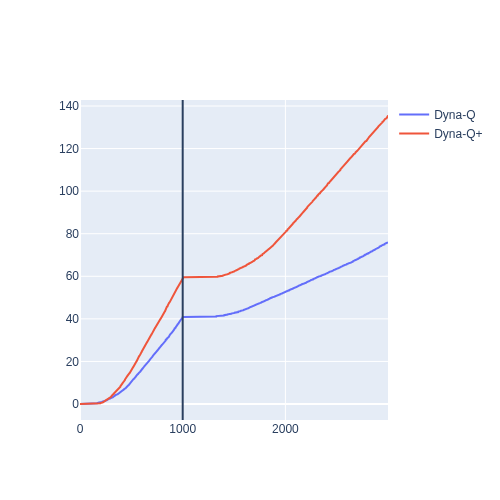

In [31]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=dynaQDBM, name="Dyna-Q"))
fig.add_trace(go.Scatter(y=dynaQPlusDBM, name="Dyna-Q+"))
fig.add_vline(x=nSwitch)
fig.update_layout(width=500)

# Example 8.3 : Shortcut Maze

In [32]:
maxRowsDSM, maxColsDSM = 6, 9
shortcutMaze1 = np.ones((maxRowsDSM, maxColsDSM), dtype=bool)
shortcutMaze1[3, 1:] = False
shortcutMaze2 = np.ones((maxRowsDSM, maxColsDSM), dtype=bool)
shortcutMaze2[3, 1:8] = False
startPosDSM = (5, 3)
endPosDSM = (0, 8)
UP, DOWN, RIGHT, LEFT = 0, 1, 2, 3

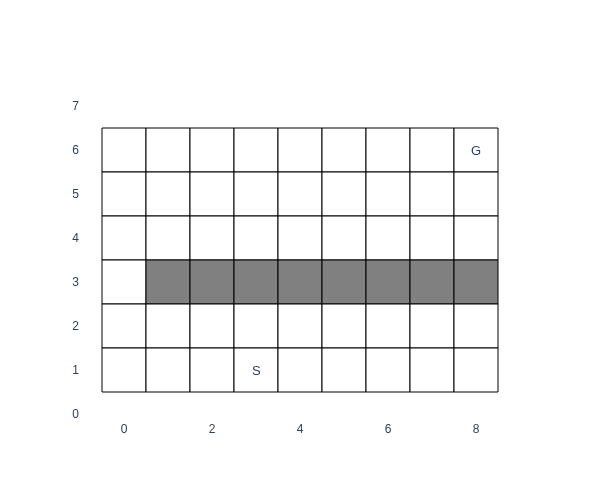

In [33]:
plotMaze(shortcutMaze1, startPosDSM, endPosDSM)

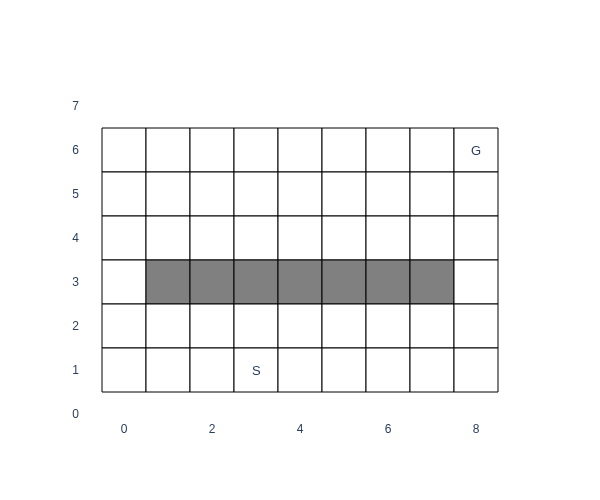

In [34]:
plotMaze(shortcutMaze2, startPosDSM, endPosDSM)

In [35]:
nStepMax = 6000
nStatesDSM = maxColsDSM * maxRowsDSM
availableActionsDSM = [UP, DOWN, RIGHT, LEFT]
qInitDSM = np.zeros((nStatesDSM, len(availableActionsDSM)))
modelInitDSM = {}
modelInitDSMPlus = {}
for state in range(nStatesDSM):
    for action in availableActionsDSM:
        modelInitDSMPlus[encodeStateAction(state, action, len(availableActionsDSM))] = (0, state)
nPlanningDSM = 50
nSwitchDSM = 3000
nRepsDSM = 10
alphaDSM = 1

dynaQDSM = []
dynaQPlusDSM = []
for rep in range(nRepsDSM):
    dynaQDSM.append(tabularDynaQDBM(nStepMax, qInitDSM, modelInitDSM, nPlanningDSM, nSwitchDSM, shortcutMaze1, shortcutMaze2, alpha=alphaDSM))
    dynaQPlusDSM.append(tabularDynaQPlusDBM(nStepMax, qInitDSM, modelInitDSMPlus, nPlanningDSM, nSwitchDSM, shortcutMaze1, shortcutMaze2, kappa=1e-3, alpha=alphaDSM))

dynaQDSM = np.mean(dynaQDSM, axis=0)
dynaQPlusDSM = np.mean(dynaQPlusDSM, axis=0)

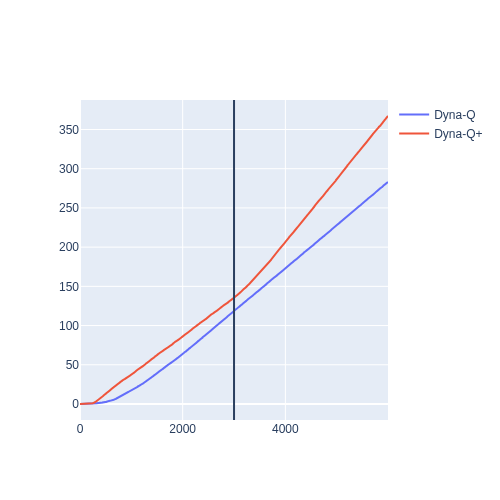

In [36]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=dynaQDSM, name="Dyna-Q"))
fig.add_trace(go.Scatter(y=dynaQPlusDSM, name="Dyna-Q+"))
fig.add_vline(x=nSwitchDSM)
fig.update_layout(width=500)

## Exercise 8.4

In [37]:
def tabularDynaQPlusSelectionDBM(nStepMax, qInit, modelInit, nPlanning, nSwitch, maze1, maze2, kappa=0.001, alpha=0.1, gamma=0.95, availableActions=[UP, DOWN, RIGHT, LEFT]):
    Q = qInit.copy()
    model = modelInit.copy()
    nSteps = 0
    visited = set()
    visitedList = []
    currentMaze = maze1
    rewards = []
    tau = np.zeros(Q.shape, dtype=int)

    while nSteps < nStepMax:
        currentPosition = startPosDBM
        traj = [currentPosition]
        currentState = encodeState(currentPosition, maxColsDBM)
        terminal = False
        t = 0
        while not terminal and nSteps < nStepMax:
            if nSteps == nSwitch:
                currentMaze = maze2

            currentAction = np.random.choice([action for action in availableActions 
                                              if (Q[currentState, action] + kappa * (tau[currentState, action] ** 0.5) == np.max(Q[currentState] + kappa * (tau[currentState] ** 0.5)))])

            if currentState not in visited:
                visited.add(currentState)
                visitedList.append(currentState)

            t += 1
            nextPosition = deriveNextState(currentPosition, currentAction, maxRowsDBM, maxColsDBM)
            nSteps += 1

            if not currentMaze[*nextPosition]:
                nextPosition = currentPosition

            nextState = encodeState(nextPosition, maxColsDBM)
            if nextPosition == endPosDBM:
                terminal = True
                reward = 1

            else:
                reward = 0

            rewards.append(reward)

            Q[currentState, currentAction] += alpha * (reward + gamma * np.max(Q[nextState]) - Q[currentState, currentAction])

            stateAction = encodeStateAction(currentState, currentAction, len(availableActions))
            model[stateAction] = (reward, nextState)
            tau += 1
            tau[currentState, currentAction] = 0

            for n in range(nPlanning):
                state = np.random.choice(visitedList)
                action = np.random.choice(availableActions)
                reward, statePrime = model[encodeStateAction(state, action, len(availableActions))]
                Q[state, action] += alpha * (reward + gamma * np.max(Q[statePrime]) - Q[state, action])
            currentState = nextState
            currentPosition = decodeState(currentState, maxColsDBM)
            traj.append(currentPosition)
           
    return np.cumsum(rewards)

In [38]:
dynaQPlusSelectionDSM = []
for rep in range(nRepsDSM):
    dynaQPlusSelectionDSM.append(tabularDynaQPlusSelectionDBM(nStepMax, qInitDSM, modelInitDSMPlus, nPlanningDSM, nSwitchDSM, shortcutMaze1, shortcutMaze2, kappa=1e-3, alpha=alphaDSM))

dynaQPlusSelectionDSM = np.mean(dynaQPlusSelectionDSM, axis=0)

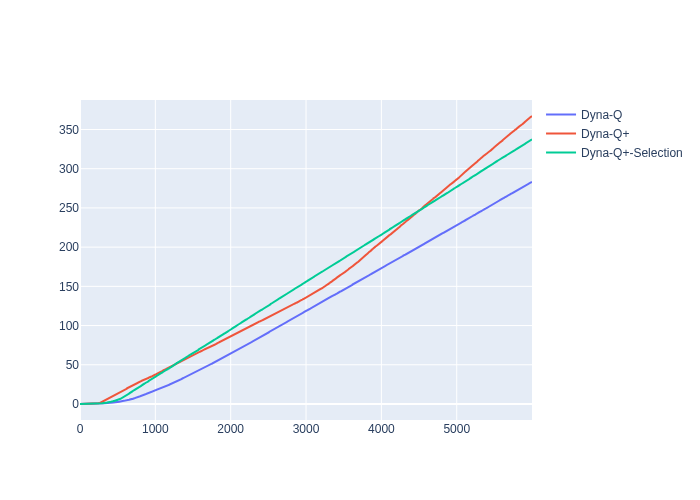

In [39]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=dynaQDSM, name="Dyna-Q"))
fig.add_trace(go.Scatter(y=dynaQPlusDSM, name="Dyna-Q+"))
fig.add_trace(go.Scatter(y=dynaQPlusSelectionDSM, name="Dyna-Q+-Selection"))
fig.update_layout(width=700)

# Trajectory sampling

In [40]:
def generateInstance(nStates, branchingFactor):
    transitionMapping = {}
    rewards = {}
    for state in range(nStates):
        action1Successors = sorted(np.random.choice(nStates, size=branchingFactor, replace=False))
        action2Successors = sorted(np.random.choice(nStates, size=branchingFactor, replace=False))
        transitionMapping[2 * state] = action1Successors
        transitionMapping[2 * state + 1] = action2Successors
        rewards[2 * state] = np.random.normal(size=branchingFactor)
        rewards[2 * state + 1] = np.random.normal(size=branchingFactor)

    return nStates, branchingFactor, transitionMapping, rewards

In [41]:
def Ld(MDP, s, a, V, gamma=1):
    nStates, branchingFactor, transitionMapping, rewards = MDP
    return 0.9 * np.sum(rewards[2 * s + a] + V[transitionMapping[2 * s + a]]) / branchingFactor

def policyEval(MDP, policy, V, theta=0.001, gamma=1):
    nStates, branchingFactor, transitionMapping, rewards = MDP
    converged = False
    while not converged:
        delta = 0
        for s in np.arange(nStates):
            v = V[s]
            V[s] = Ld(MDP, s, policy[s], V, gamma)
            delta = max(delta, abs(v - V[s]))
        converged = delta < theta

In [42]:
def policyEvalMC(MDP, policy, nEpisodes):
    nStates, branchingFactor, transitionMapping, rewards = MDP
    gains = []
    for i in range(nEpisodes):
        currentState = 0
        terminal = False
        gain = 0
        while not terminal:
            currentAction = policy[currentState]
            nextStateId = np.random.choice(branchingFactor + 1, p=[0.9 / branchingFactor] * branchingFactor + [0.1])
            
            if nextStateId == branchingFactor:
                terminal = True
                break
            else:
                gain += rewards[2 * currentState + currentAction][nextStateId]
                currentState = transitionMapping[2 * currentState + currentAction][nextStateId]
        gains.append(gain)
    return np.mean(gains)

In [43]:
def uniformTSUpdates(MDP, qInit, nIters, evalStep, nEvalEpsiodes):
    nStates, branchingFactor, transitionMapping, rewards = MDP
    Q = qInit.copy()
    Q[-1, :] = 0 # terminal value always set to 0
    V = np.zeros(nStates + 1)
    greedyPolicy = np.random.choice([0, 1], size=nStates)
    vStartState = [0]
    nSweeps = nIters // (2 * nStates)
    t = 0
    for n in range(nSweeps):
        for state in range(nStates):
            Q[state, 0] = 0.9 * np.sum((rewards[2 * state] + np.max(Q[transitionMapping[2 * state]], axis=1))) / branchingFactor
            greedyPolicy[state] = np.random.choice([action for action in [0, 1] if Q[state, action] == np.max(Q[state])])
            t += 1
            if t % evalStep == 0:
                # policyEval(MDP, greedyPolicy, V)
                vStartState.append(policyEvalMC(MDP, greedyPolicy, nEvalEpsiodes))

            Q[state, 1] = 0.9 * np.sum((rewards[2 * state + 1] + np.max(Q[transitionMapping[2 * state + 1]], axis=1))) / branchingFactor
            greedyPolicy[state] = np.random.choice([action for action in [0, 1] if Q[state, action] == np.max(Q[state])])
            t += 1
            if t % evalStep == 0:
                # policyEval(MDP, greedyPolicy, V)
                vStartState.append(policyEvalMC(MDP, greedyPolicy, nEvalEpsiodes))

    return vStartState

In [44]:
def onPolicyTSUpdate(MDP, qInit, nIters, evalStep, nEvalEpsiodes, epsilon=0.1, alpha=1):
    nStates, branchingFactor, transitionMapping, rewards = MDP
    Q = qInit.copy()
    Q[-1, :] = 0
    V = np.zeros(nStates + 1)
    greedyPolicy = np.random.choice([0, 1], size=nStates)
    vStartState = [0]
    t = 0
    while t < nIters:
        currentState = 0
        terminal = False
        while not terminal and t < nIters:
            if np.random.rand() < epsilon:
                currentAction = np.random.choice([0, 1])
            else:
                currentAction = np.random.choice([action for action in [0, 1] if Q[currentState, action] == np.max(Q[currentState])])

            nextStateId = np.random.choice(branchingFactor + 1, p=[0.9 / branchingFactor] * branchingFactor + [0.1])
            if nextStateId == branchingFactor:
                terminal = True
                nextState = nStates
            else:
                nextState = transitionMapping[2 * currentState + currentAction][nextStateId]

            Q[currentState, currentAction] = 0.9 * np.sum((rewards[2 * currentState + currentAction] + np.max(Q[transitionMapping[2 * currentState + currentAction]], axis=1))) / branchingFactor

            t += 1
            greedyPolicy[currentState] = np.random.choice([action for action in [0, 1] if Q[currentState, action] == np.max(Q[currentState])])
            if t % evalStep == 0:
                # policyEval(MDP, greedyPolicy, V)
                vStartState.append(policyEvalMC(MDP, greedyPolicy, nEvalEpsiodes))

            currentState = nextState
                
    return vStartState

In [ ]:
nStatesTS = 1000
qInitTS = np.zeros((nStatesTS + 1, 2))
evalStep = 10
nEvalEpisodes = 100
nUpdates = 20000
nReps = 200
bTSs = [1, 3, 10]
avgUniform = {}
avgOnPolicy = {}
for b in bTSs:
    uniformStartStateValues = []
    onPolicyStartStateValues = []

    for rep in range(nReps):
        MDP = generateInstance(nStatesTS, b)
        uniformStartStateValues.append(uniformTSUpdates(MDP, qInitTS, nUpdates, evalStep, nEvalEpisodes))
        onPolicyStartStateValues.append(onPolicyTSUpdate(MDP, qInitTS, nUpdates, evalStep, nEvalEpisodes))

    avgUniform[b] = np.mean(uniformStartStateValues, axis=0)
    avgOnPolicy[b] = np.mean(onPolicyStartStateValues, axis=0)


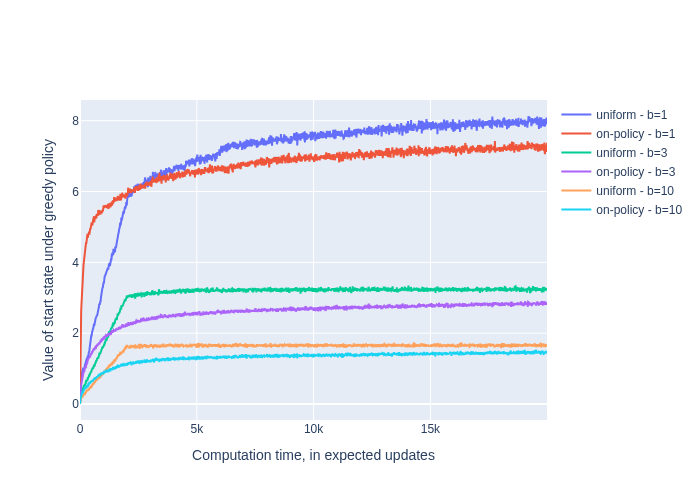

In [47]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[1], name="uniform - b=1"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[1], name="on-policy - b=1"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[3], name="uniform - b=3"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[3], name="on-policy - b=3"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[10], name="uniform - b=10"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[10], name="on-policy - b=10"))
fig.update_layout(xaxis_title="Computation time, in expected updates", yaxis_title="Value of start state under greedy policy", width=700)

In [ ]:
nStatesTS = 10000
qInitTS = np.zeros((nStatesTS + 1, 2))
evalStep = 100
nEvalEpisodes = 100
nUpdates = 200000
nReps = 200
bTSs = [1, 3, 10]
avgUniform = {}
avgOnPolicy = {}
for b in bTSs:
    uniformStartStateValues = []
    onPolicyStartStateValues = []

    for rep in range(nReps):
        MDP = generateInstance(nStatesTS, b)
        uniformStartStateValues.append(uniformTSUpdates(MDP, qInitTS, nUpdates, evalStep, nEvalEpisodes))
        onPolicyStartStateValues.append(onPolicyTSUpdate(MDP, qInitTS, nUpdates, evalStep, nEvalEpisodes))

    avgUniform[b] = np.mean(uniformStartStateValues, axis=0)
    avgOnPolicy[b] = np.mean(onPolicyStartStateValues, axis=0)

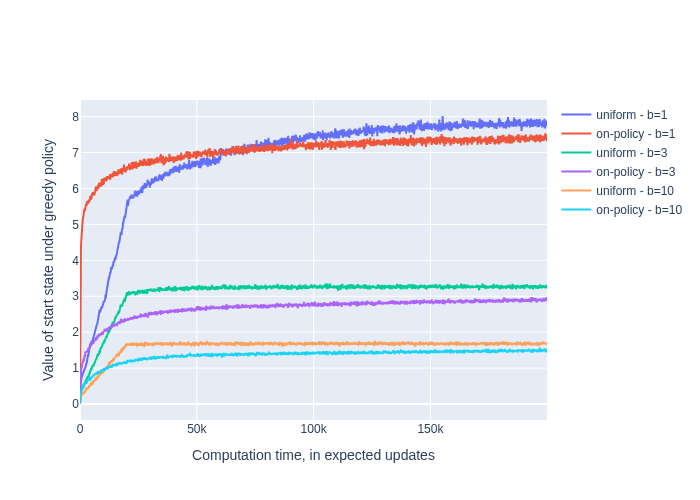

In [50]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[1], name="uniform - b=1"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[1], name="on-policy - b=1"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[3], name="uniform - b=3"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[3], name="on-policy - b=3"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgUniform[10], name="uniform - b=10"))
fig.add_trace(go.Scatter(x=np.arange(0, nUpdates, evalStep), y=avgOnPolicy[10], name="on-policy - b=10"))
fig.update_layout(xaxis_title="Computation time, in expected updates", yaxis_title="Value of start state under greedy policy", width=700)